# 1.1 Exercise 1: SVD Implementation from Scratch

In [1]:
import numpy as np

In [2]:
def svd_form(A):
    m, n = A.shape
    L = A @ A.T
    leigen_vals, leigen_vecs = np.linalg.eig(L)
    left_idx = np.argsort(-leigen_vals)
    sorted_vals = leigen_vals[left_idx]
    U = leigen_vecs[:, left_idx]
    S = np.zeros_like(A).astype(float)
    for i in range(min(m,n)):
        S[i,i] = np.sqrt(sorted_vals[i])

    R = A.T @ A
    reigen_vals, reigen_vecs = np.linalg.eig(R)
    right_idx = np.argsort(-reigen_vals)
    sorted_right_vecs = reigen_vecs[:, right_idx]
    vectors = []
    for i in range(n):
        v_i = sorted_right_vecs[:, i]
        if i < m:
            u_i = U[:, i]
            s_i = S[i, i]
            if np.allclose(A.T@u_i, s_i*v_i):
                vectors.append(v_i)
            else:
                vectors.append(-v_i)
        else:
            vectors.append(v_i)

    return U, S, np.array(vectors)

In [3]:
a = np.random.randint(low=-3, high=3, size=(15, 20))
u, s, vt = svd_form(a)
np.allclose(a, u @ (s @ vt))

/var/folders/_b/zt2whyhx3n906g8v4hwq50hw0000gn/T/ipykernel_52730/136632712.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  S[i,i] = np.sqrt(sorted_vals[i])


True

In [4]:
b = np.random.randint(low=-3, high=3, size=(25, 10))
u, s, vt = svd_form(b)
np.allclose(b, u @ (s @ vt))

/var/folders/_b/zt2whyhx3n906g8v4hwq50hw0000gn/T/ipykernel_52730/136632712.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  S[i,i] = np.sqrt(sorted_vals[i])


True

# 1.2 Exercise 2: Image Processing with Low-Rank Approximation

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

In [6]:
img = Image.open("img.jpg").convert("L")
img_arr = np.array(img)

In [7]:
U, S, VT = np.linalg.svd(img_arr, full_matrices=False)
k_vals = np.arange(10, 101, 5)

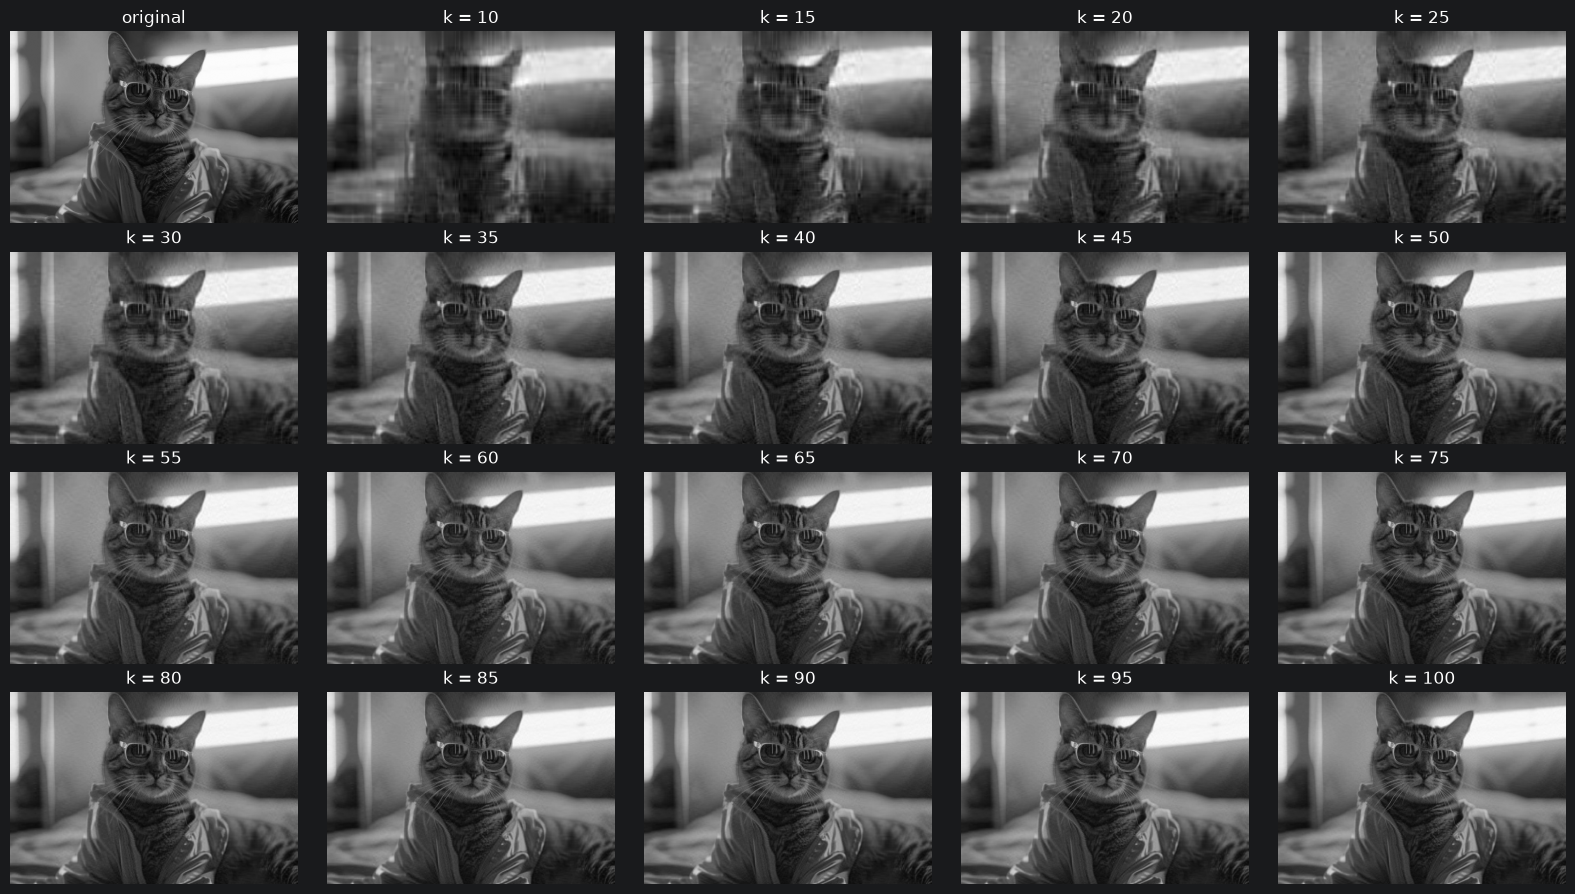

In [8]:
fig, axs = plt.subplots(nrows=4, ncols=5, figsize=(16, 9))

axs[0, 0].imshow(img_arr, cmap="gray")
axs[0, 0].set_title("original")
axs[0, 0].set_axis_off()

for i, k in enumerate(k_vals, start=1):
    row_idx = i // 5
    col_idx = i % 5
    U_k = U[:, :k]
    S_k = np.diag(S[:k])
    VT_k = VT[:k, :]
    img_k = np.real(U_k @ (S_k @ VT_k))
    axs[row_idx, col_idx].imshow(img_k, cmap="gray")
    axs[row_idx, col_idx].set_title(f"k = {k}")
    axs[row_idx, col_idx].set_axis_off()

plt.tight_layout()
plt.show()